## 1. Import Libraries

In [1]:
import os
import re
import string
import sys
from datetime import datetime
import seaborn as sns
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from langdetect import DetectorFactory, detect_langs
from langdetect.lang_detect_exception import LangDetectException
from langdetect import detect_langs, DetectorFactory


from nltk.corpus import stopwords
from nltk.util import ngrams
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from collections import Counter

DetectorFactory.seed = 42

# Konfigurasi display pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 200)

print("Libraries berhasil dimuat.")

Libraries berhasil dimuat.


## 2. Scraping Data

In [2]:
from google_play_scraper import reviews, Sort

csv_filename = "raw_satusehat.csv"

# Load existing dataset or scrape new reviews
if os.path.exists(csv_filename):
    df = pd.read_csv(csv_filename)
    print("Loading existing raw dataset...")

else:
    all_reviews, token = [], None

    while len(all_reviews) < 20000:
        batch, token = reviews(
            "com.telkom.tracencare",
            lang="id",
            country="id",
            sort=Sort.NEWEST,
            count=200,
            continuation_token=token
        )

        if not batch:
            break

        all_reviews.extend(batch)

        if token is None:
            break

    df = pd.DataFrame(all_reviews[:20000])
    df = df[["content", "score", "at", "appVersion"]]

    df.to_csv(
        csv_filename,
        index=False,
        encoding="utf-8-sig"
    )

    print("Scraping completed and saved.")

print("Total reviews:", len(df))
display(df.head())


Loading existing raw dataset...
Total reviews: 20000


,content,score,at,appVersion
0,ssehat bereng satu sehat,5,2026-11-17 12:40:01,8.11.0
1,"Kalian tidak usah bikin aplikasi kalau gaptek, ini aplikasi tidak bisa login, reset password tidak bisa, masuk otp salah terus!! Buat apa ada aplikasi kalau tidak bisa difungsikan!!",1,2026-11-17 07:32:08,8.11.0
2,kenapa sekarang tidak bisa log in,1,2026-11-17 05:43:22,8.11.0
3,"sertifikat vaksin tidak bisa di unduh, sudah buat formulir aduan juga sama saja tidak ada jawaban. hadeh",1,2026-11-16 15:47:30,8.11.0
4,sangat informatif,4,2026-11-16 10:12:39,8.10.2


## 3. EDA

#### 3.1 Dataset Overview

In [3]:
df.head()

,content,score,at,appVersion
0,ssehat bereng satu sehat,5,2026-11-17 12:40:01,8.11.0
1,"Kalian tidak usah bikin aplikasi kalau gaptek, ini aplikasi tidak bisa login, reset password tidak bisa, masuk otp salah terus!! Buat apa ada aplikasi kalau tidak bisa difungsikan!!",1,2026-11-17 07:32:08,8.11.0
2,kenapa sekarang tidak bisa log in,1,2026-11-17 05:43:22,8.11.0
3,"sertifikat vaksin tidak bisa di unduh, sudah buat formulir aduan juga sama saja tidak ada jawaban. hadeh",1,2026-11-16 15:47:30,8.11.0
4,sangat informatif,4,2026-11-16 10:12:39,8.10.2


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   content     20000 non-null  str  
 1   score       20000 non-null  int64
 2   at          20000 non-null  str  
 3   appVersion  14919 non-null  str  
dtypes: int64(1), str(3)
memory usage: 625.1 KB


In [5]:
df["at"] = pd.to_datetime(df["at"])
df.describe()

,score,at
count,20000.000000,20000
mean,2.039000,2024-06-16 13:50:21.548600
min,1.000000,2023-04-09 17:34:09
25%,1.000000,2023-07-22 19:10:13
50%,1.000000,2024-03-24 20:51:23
75%,3.000000,2025-03-18 16:59:17.250000
max,5.000000,2026-11-17 12:40:01
std,1.631843,NaN


Dataset hasil scraping Google Play Store terdiri dari **20.000 ulasan** dengan dua atribut yang ditampilkan dalam statistik deskriptif, yaitu `score` dan `at`. Seluruh data memiliki rating dan tanggal publikasi. Berdasarkan statistik deskriptif, rata-rata rating yang diberikan pengguna adalah **2,04 dari 5**, dengan nilai minimum 1 dan maksimum 5. Periode ulasan dimulai pada **9 April 2023 hingga 17 November 2026**.

#### 3.2 Cek Missing Value & Duplicated

In [6]:
print("Jumlah ulasan        :", len(df))
print("Ulasan kosong (NaN)  :", df["content"].isna().sum())
print("Ulasan duplikat      :", df["content"].duplicated().sum())

Jumlah ulasan        : 20000
Ulasan kosong (NaN)  : 0
Ulasan duplikat      : 2237


Berdasarkan pemeriksaan awal, dataset terdiri dari **20.000 ulasan** tanpa adanya nilai kosong (*missing value*) pada kolom teks ulasan. Namun, ditemukan sebanyak **2.237 ulasan duplikat** yang berpotensi memengaruhi kualitas dan konsistensi analisis. Penanganan terhadap ulasan duplikat akan dilakukan pada tahap **Data Preprocessing** untuk memastikan setiap ulasan yang digunakan merepresentasikan data yang unik.

#### 3.3 Language Detect

In [7]:
# Language Detection
language_filename = "satusehat_with_language.csv"

if os.path.exists(language_filename):
    df = pd.read_csv(language_filename)
    print("Loading existing language dataset...")

else:
    DetectorFactory.seed = 42

    # Language detection function
    def detect_language(text):
        try:
            languages = detect_langs(text)

            id_prob = 0
            en_prob = 0

            for lang in languages:
                if lang.lang == "id":
                    id_prob = lang.prob
                elif lang.lang == "en":
                    en_prob = lang.prob

            if id_prob >= 0.15 and en_prob >= 0.15:
                return "Indonesian-English Mixed"
            elif id_prob > en_prob:
                return "Indonesian"
            elif en_prob > id_prob:
                return "English"
            else:
                return "Other / Unknown"

        except LangDetectException:
            return "Other / Unknown"

    # Apply language detection
    df["language"] = df["content"].apply(detect_language)

    # Save language detection results
    df.to_csv(
        language_filename,
        index=False,
        encoding="utf-8-sig"
    )

    print("Language detection completed and saved.")

print("Total reviews:", len(df))
display(df["language"].value_counts(dropna=False))


Loading existing language dataset...
Total reviews: 20000


language
Indonesian                  16883
Other / Unknown              2828
English                       275
Indonesian-English Mixed       14
Name: count, dtype: int64

In [8]:
# Calculate the number and percentage of reviews for each language
language_distribution = (
    df["language"]
    .value_counts()
    .reset_index()
)

language_distribution.columns = ["Language", "Total Reviews"]

language_distribution["Percentage"] = (
    language_distribution["Total Reviews"] / len(df) * 100
).round(2)

display(language_distribution)

,Language,Total Reviews,Percentage
0,Indonesian,16883,84.42
1,Other / Unknown,2828,14.14
2,English,275,1.38
3,Indonesian-English Mixed,14,0.07


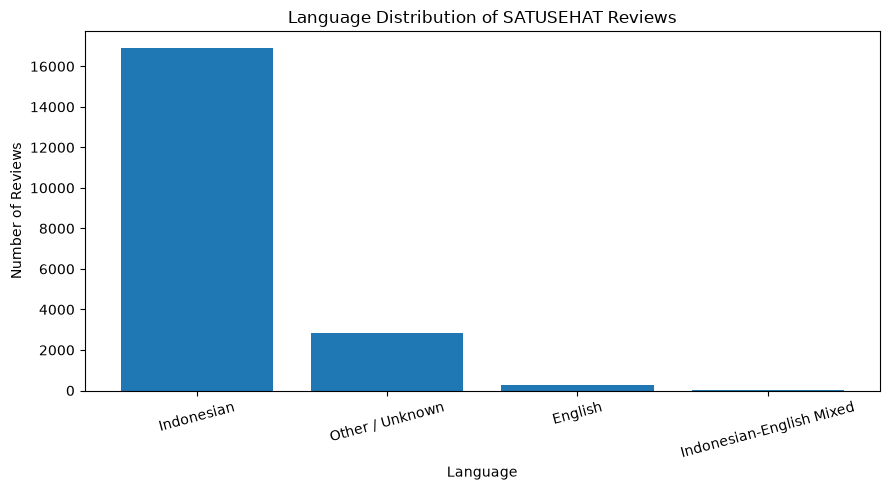

In [9]:
# Create bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    language_distribution["Language"],
    language_distribution["Total Reviews"]
)

plt.title("Language Distribution of SATUSEHAT Reviews")
plt.xlabel("Language")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

Berdasarkan hasil deteksi bahasa, sebanyak **16.883 ulasan (84,43%)** teridentifikasi menggunakan Bahasa Indonesia, **275 ulasan (14,14%)** menggunakan Bahasa Inggris, **2828 ulasan (84,43%)** teridentifikasi menggunakan Bahasa Lainnya dan **14 ulasan (0,07%)** merupakan campuran Bahasa Indonesia-Inggris. Pada tahap preprocessing, penelitian ini akan **mempertahankan ulasan berbahasa Indonesia, termasuk penggunaan istilah teknis berbahasa Inggris yang relevan** seperti *login*, *OTP*, dan *error*. Ulasan yang sepenuhnya menggunakan bahasa asing dan tidak memenuhi kriteria penelitian akan dieliminasi.

#### 3.4 Review Date Distribution

Review di luar periode: 181
Total review: 19819

Distribusi Review per Tahun:
at
2023    7884
2024    6117
2025    4037
2026    1781
Name: count, dtype: int64


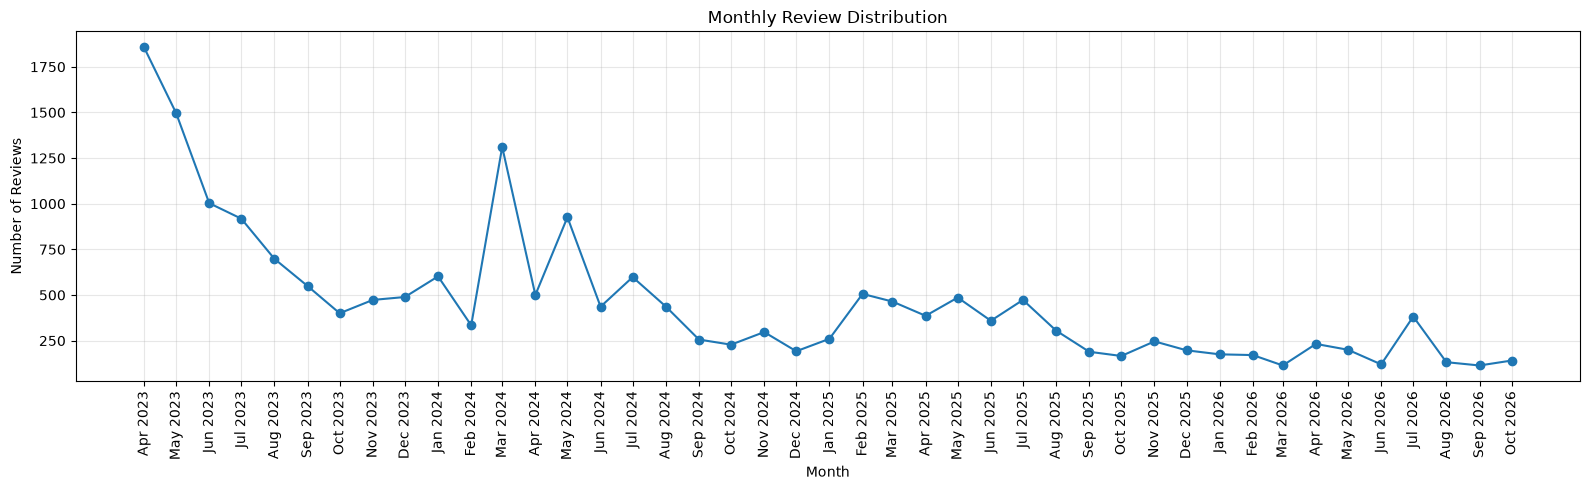

In [10]:
# Filter periode penelitian
df['at'] = pd.to_datetime(df['at'], errors='coerce')

df_period = df[df['at'].between('2023-03-01', '2026-10-31')].copy()

# Cek review di luar periode
print("Review di luar periode:", len(df) - len(df_period))
print("Total review:", len(df_period))

# Distribusi review per tahun
print("\nDistribusi Review per Tahun:")
print(df_period['at'].dt.year.value_counts().sort_index())

# Distribusi review per bulan
monthly_reviews = (
    df_period.set_index('at')
    .resample('MS')
    .size()
)

# Visualisasi
plt.figure(figsize=(16, 5))
plt.plot(monthly_reviews.index, monthly_reviews.values, marker='o')

plt.title('Monthly Review Distribution')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.xticks(monthly_reviews.index, monthly_reviews.index.strftime('%b %Y'), rotation=90)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Berdasarkan distribusi bulanan, jumlah ulasan cenderung mengalami penurunan dari April 2023 hingga Oktober 2026, meskipun terdapat beberapa peningkatan signifikan, terutama pada Maret dan Mei 2024. Pada tahap *data preprocessing*, akan dilakukan **filtering berdasarkan periode penelitian**, yaitu mempertahankan ulasan yang dipublikasikan mulai **1 Maret 2023 hingga 31 Oktober 2026** dan menghapus ulasan di luar rentang tersebut.

#### 3.5 Rating Distribution

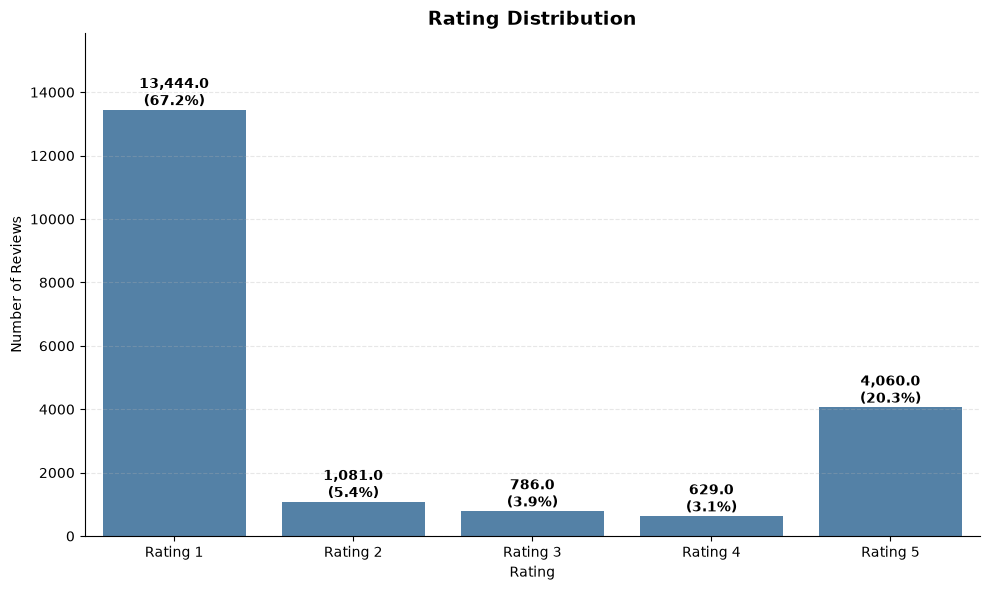

In [11]:
# Memastikan score bertipe numerik
df["score"] = pd.to_numeric(df["score"], errors="coerce")

# Menghitung jumlah rating 1-5
rating_counts = (
    df["score"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
)

# Menghitung persentase
rating_percentages = rating_counts / rating_counts.sum() * 100

# Membuat DataFrame visualisasi
rating_data = pd.DataFrame({
    "Rating": [1, 2, 3, 4, 5],
    "Total Reviews": rating_counts.values,
    "Percentage": rating_percentages.values
})

# Visualisasi
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=rating_data,
    x="Rating",
    y="Total Reviews",
    order=[1, 2, 3, 4, 5],
    color="steelblue"
)

# Anotasi jumlah dan persentase
for i, row in rating_data.iterrows():
    ax.text(
        i,
        row["Total Reviews"],
        f'{row["Total Reviews"]:,}\n({row["Percentage"]:.1f}%)',
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Rating Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(range(5), [f"Rating {i}" for i in range(1, 6)])
plt.ylim(0, rating_data["Total Reviews"].max() * 1.18)
plt.grid(axis="y", linestyle="--", alpha=0.3)

sns.despine()
plt.tight_layout()
plt.show()

Distribusi rating didominasi oleh **Rating 1 sebanyak 13.444 review (67,2%)**, diikuti Rating 5 sebanyak 4.060 review (20,3%). Hal ini menunjukkan bahwa mayoritas users memberikan penilaian rendah terhadap SATUSEHAT Mobile, yang mengindikasikan kecenderungan pengalaman pengguna yang kurang memuaskan.

#### 3.6 Review Length Analysis

In [12]:
# Membuat fitur panjang review
df["word_count"] = df["content"].fillna("").astype(str).apply(lambda x: len(x.split()))
df["char_count"] = df["content"].fillna("").astype(str).apply(len)

In [13]:
# Statistik deskriptif panjang review
print("=== REVIEW LENGTH STATISTICS ===")

print(f"Total Reviews       : {len(df):,}")
print(f"Average Word Count  : {df['word_count'].mean():.2f} words")
print(f"Median Word Count   : {df['word_count'].median():.0f} words")
print(f"Shortest Review     : {df['word_count'].min()} words")
print(f"Longest Review      : {df['word_count'].max()} words")

print(f"\nAverage Char Count  : {df['char_count'].mean():.2f} characters")
print(f"Median Char Count   : {df['char_count'].median():.0f} characters")
print(f"Shortest Review     : {df['char_count'].min()} characters")
print(f"Longest Review      : {df['char_count'].max()} characters")

=== REVIEW LENGTH STATISTICS ===
Total Reviews       : 20,000
Average Word Count  : 13.46 words
Median Word Count   : 10 words
Shortest Review     : 1 words
Longest Review      : 97 words

Average Char Count  : 83.26 characters
Median Char Count   : 59 characters
Shortest Review     : 1 characters
Longest Review      : 500 characters


In [14]:
# Menampilkan review terpendek dan terpanjang
shortest_review = df.loc[df["word_count"].idxmin(), "content"]
longest_review = df.loc[df["word_count"].idxmax(), "content"]

print("=== SHORTEST REVIEW ===")
print(shortest_review)

print("\n=== LONGEST REVIEW ===")
print(longest_review)

# Persentase review yang memenuhi minimal 5 kata
valid_reviews = (df["word_count"] >= 5).sum()
invalid_reviews = (df["word_count"] < 5).sum()

print("\n=== MINIMUM 5-WORD REQUIREMENT ===")
print(f"Reviews >= 5 words : {valid_reviews:,} ({valid_reviews / len(df) * 100:.2f}%)")
print(f"Reviews < 5 words  : {invalid_reviews:,} ({invalid_reviews / len(df) * 100:.2f}%)")

=== SHORTEST REVIEW ===
good

=== LONGEST REVIEW ===
Sy merasa blm pernah mendaftar satu sehat jd sy daftar & ternyata menurut aplikasi sy sdh terdaftar shg butuh PIN 6 angka untuk login. Sy ga tau dong PIN nya apa, jd sy pencet "lupa PIN", lalu ada kode dikirim ke email, sudah 3x copy paste kode salah terus. Kmd sy coba klik "lupa Akun", malah diarahkan ganti email. Di email baru ada kode lagi, sy copy paste, berhasil & buat PIN baru. Eh abis itu malah otomatis kaya log out & pas sy cb login lgi gagal, krn sdh 5x percobaan. Cape bgt mo login 😩

=== MINIMUM 5-WORD REQUIREMENT ===
Reviews >= 5 words : 14,210 (71.05%)
Reviews < 5 words  : 5,790 (28.95%)


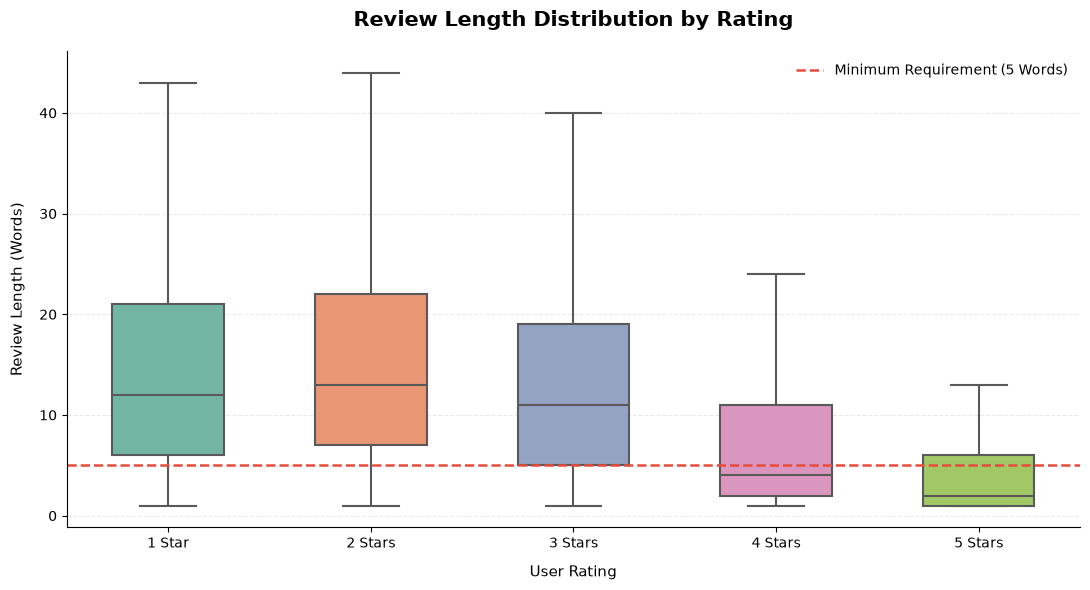

In [15]:
plt.figure(figsize=(11, 6))

ax = sns.boxplot(
    data=df,
    x="score",
    y="word_count",
    hue="score",
    order=[1, 2, 3, 4, 5],
    palette="Set2",
    width=0.55,
    linewidth=1.5,
    showfliers=False,
    legend=False
)

plt.axhline(
    y=5,
    color="#E74C3C",
    linestyle="--",
    linewidth=1.8,
    label="Minimum Requirement (5 Words)"
)

plt.title(
    "Review Length Distribution by Rating",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.xlabel("User Rating", fontsize=11, labelpad=10)
plt.ylabel("Review Length (Words)", fontsize=11, labelpad=10)

plt.xticks(
    [0, 1, 2, 3, 4],
    ["1 Star", "2 Stars", "3 Stars", "4 Stars", "5 Stars"]
)

plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.legend(frameon=False, loc="upper right")

sns.despine()
plt.tight_layout()
plt.show()

Berdasarkan hasil analisis, rata-rata panjang review adalah **13,46 kata**, dengan median 10 kata, sedangkan panjang review berkisar antara 1 hingga 97 kata. Dari total 20.000 review, sebanyak **14.210 (71,05%)** memiliki minimal lima kata, sementara 5.790 (28,95%) memiliki kurang dari lima kata. Oleh karena itu, pada tahap *data preprocessing* akan dilakukan filtering dengan mempertahankan review yang memiliki **minimal lima kata** dan menghapus review yang tidak memenuhi kriteria sesuai ketentuan dalam penelitian.

#### 3.7 Dominant Word Analysis

##### 3.7.1 Stopword Preparation

In [16]:
# Stopwords NLTK dan Sastrawi
stopwordIndonesiaNLTK = set(stopwords.words('indonesian'))
stopwordSastrawi = set(StopWordRemoverFactory().get_stop_words())

negation_word = {
    # --- inti ---
    'tidak': 'tidak', 'tak': 'tidak', 'bukan': 'bukan',
    'belum': 'belum', 'jangan': 'jangan',

    # --- varian "tidak" ---
    'enggak': 'tidak', 'nggak': 'tidak', 'ngga': 'tidak', 'engga': 'tidak',
    'ndak': 'tidak', 'gak': 'tidak', 'ga': 'tidak', 'gk': 'tidak',
    'gag': 'tidak', 'kagak': 'tidak', 'kaga': 'tidak', 'g': 'tidak',
    'tdk': 'tidak', 'gx': 'tidak',

    # --- varian "jangan"  ---
    'jgn': 'jangan', 'janganlah': 'jangan',

    # --- negasi gabungan ---
    'gada': 'tidak ada', 'gaada': 'tidak ada', 'gamau': 'tidak mau',
    'gapapa': 'tidak apa-apa', 'gabisa': 'tidak bisa',
    'gatau': 'tidak tahu', 'gapaham': 'tidak paham',

    # --- negasi lain dari ---
    'tiada': 'tiada', 'non': 'non', 'kurang': 'kurang',
    'tanpa': 'tanpa', 'nihil': 'nihil', 'takkan': 'tidak akan',
    'bukanlah': 'bukan', 'tidaklah': 'tidak',
    'blm': 'belum', 'bkn': 'bukan', 'gbs': 'tidak bisa',
}

# Gabungkan stopwords
stopword = stopwordIndonesiaNLTK | stopwordSastrawi

# Kata negasi yang harus dipertahankan
negation_terms = set(negation_word.keys())

# Tambahkan kata hasil normalisasi negasi
negation_terms.update(
    word
    for value in negation_word.values()
    for word in value.split()
)

# Custom stopwords tambahan
custom_stopwords = {
    'nya', 'ada', 'udah', 'aja', 'sih',
    'dong', 'nih', 'deh', 'kok', 'yah','ada','bisa','mau','ada','yg',
    'banget', 'sangat', 'banyak', 'bisa','ini','di','saya','nya','sudah','susah'
}

# Gabungkan stopwords
negation_terms = negation_terms - custom_stopwords
stopword = (stopword | custom_stopwords) - negation_terms
print("Total Stopwords:", len(stopword))
print("Total Negation Words:", len(negation_word))

Total Stopwords: 770
Total Negation Words: 39


In [17]:
# Menampilkan seluruh Stopwords
print("\n" + "=" * 50)
print("DAFTAR STOPWORDS INDONESIA")
print("=" * 50)

for i, word in enumerate(sorted(stopword), start=1):
    print(f"{i}. {word}")

print("\nTotal Stopwords:", len(stopword))


DAFTAR STOPWORDS INDONESIA
1. ada
2. adalah
3. adanya
4. adapun
5. agak
6. agaknya
7. agar
8. aja
9. akankah
10. akhir
11. akhiri
12. akhirnya
13. aku
14. akulah
15. amat
16. amatlah
17. anda
18. andalah
19. antar
20. antara
21. antaranya
22. anu
23. apa
24. apaan
25. apabila
26. apakah
27. apalagi
28. apatah
29. artinya
30. asal
31. asalkan
32. atas
33. atau
34. ataukah
35. ataupun
36. awal
37. awalnya
38. bagai
39. bagaikan
40. bagaimana
41. bagaimanakah
42. bagaimanapun
43. bagi
44. bagian
45. bahkan
46. bahwa
47. bahwasanya
48. baik
49. bakal
50. bakalan
51. balik
52. banget
53. banyak
54. bapak
55. baru
56. bawah
57. beberapa
58. begini
59. beginian
60. beginikah
61. beginilah
62. begitu
63. begitukah
64. begitulah
65. begitupun
66. bekerja
67. belakang
68. belakangan
69. belumlah
70. benar
71. benarkah
72. benarlah
73. berada
74. berakhir
75. berakhirlah
76. berakhirnya
77. berapa
78. berapakah
79. berapalah
80. berapapun
81. berarti
82. berawal
83. berbagai
84. berdatangan
85. 

##### 3.7.2 Unigram Analysis

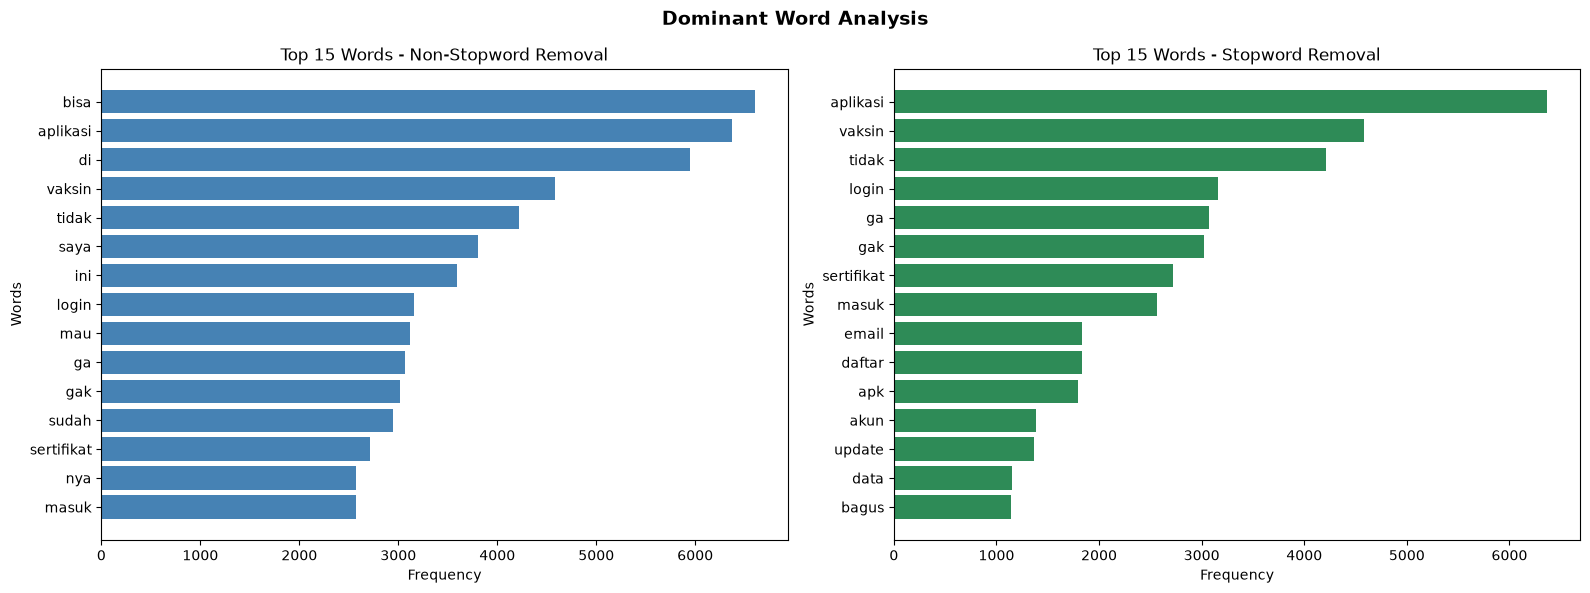

In [18]:
# Menggabungkan seluruh kata dari review
all_words = []

for review in df_period['content'].dropna().astype(str):
    review = review.lower()
    review = review.translate(str.maketrans('', '', string.punctuation))
    all_words.extend(review.split())

# Non-Stopword Removal
dominant_words_with_stopwords_df = pd.DataFrame(
    Counter(all_words).most_common(15),
    columns=['Word', 'Frequency']
)

# Stopword Removal
filtered_words = [word for word in all_words if word not in stopword]

dominant_words_no_stopwords_df = pd.DataFrame(
    Counter(filtered_words).most_common(15),
    columns=['Word', 'Frequency']
)

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, data, title, color in [
    (axes[0], dominant_words_with_stopwords_df, 'Non-Stopword Removal', 'steelblue'),
    (axes[1], dominant_words_no_stopwords_df, 'Stopword Removal', 'seagreen')
]:
    ax.barh(data['Word'][::-1], data['Frequency'][::-1], color=color)
    ax.set_title(f'Top 15 Words - {title}')
    ax.set_xlabel('Frequency')
    ax.set_ylabel('Words')

plt.suptitle('Dominant Word Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Berdasarkan hasil analisis, kata **aplikasi**, **vaksin**, **login**, dan **sertifikat** menjadi kata dominan yang menunjukkan pembahasan terkait layanan SATUSEHAT. Setelah *stopword removal*, kata yang lebih spesifik seperti **email**, **daftar**, **akun**, dan **update** menjadi lebih terlihat. Kata negasi seperti **tidak**, **ga**, dan **gak** tetap dipertahankan karena penting untuk memahami konteks keluhan pengguna. Selain itu, ditemukan variasi kata tidak baku seperti **ga** dan **gak** yang perlu dinormalisasi pada tahap preprocessing. Secara keseluruhan, hasil ini memberikan gambaran awal mengenai aspek layanan yang sering dibahas pengguna.

##### 3.7.3 Bigram Analysis

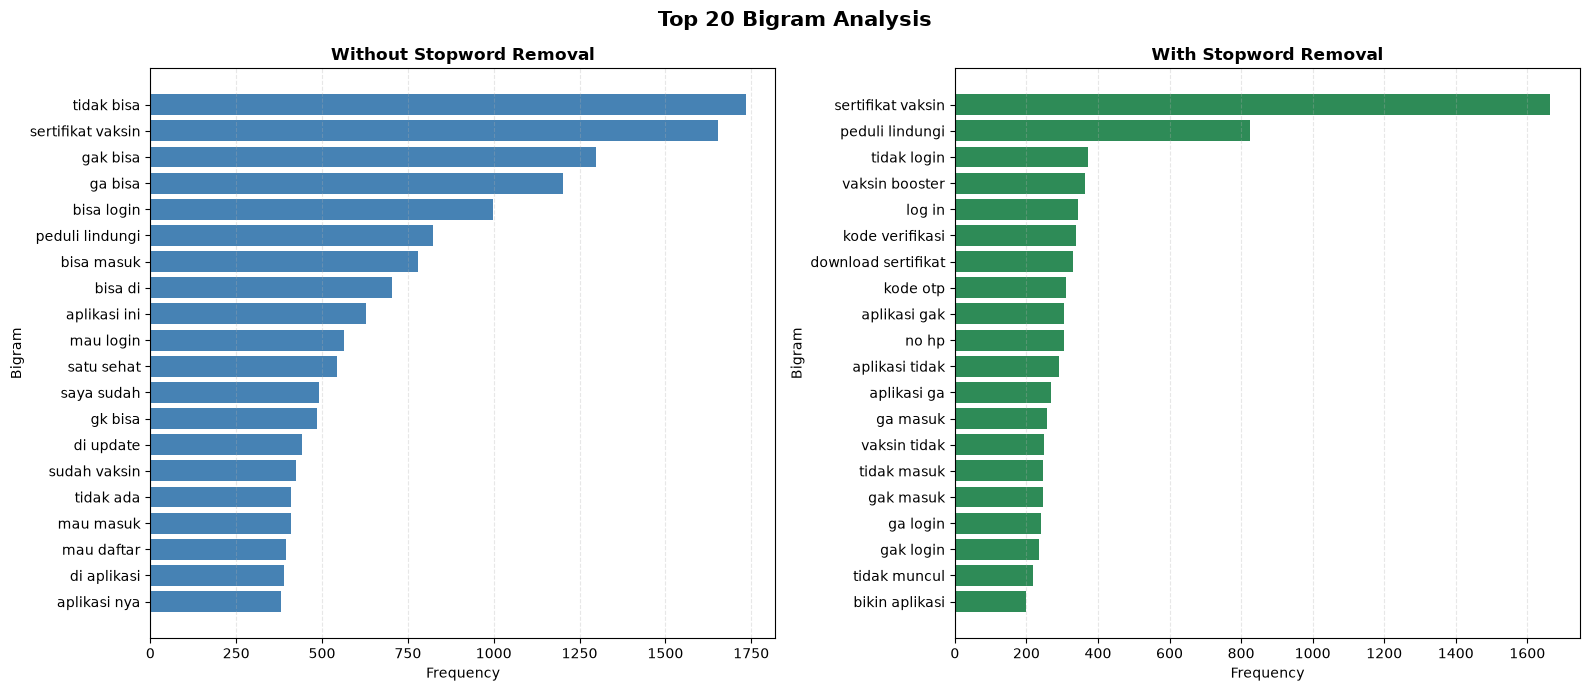

In [19]:
# Fungsi tokenisasi
def tokenize(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    return text.split()

# Mengambil token dari review
tokens_original = [tokenize(review) for review in df_period["content"].dropna()]

bigrams_original = [
    bigram
    for tokens in tokens_original
    for bigram in ngrams(tokens, 2)
]

top_bigram_original = Counter(bigrams_original).most_common(20)

tokens_filtered = [
    [word for word in tokens if word not in stopword]
    for tokens in tokens_original
]

bigrams_filtered = [
    bigram
    for tokens in tokens_filtered
    for bigram in ngrams(tokens, 2)
]

top_bigram_filtered = Counter(bigrams_filtered).most_common(20)

# Membuat DataFrame
bigram_original_df = pd.DataFrame([(" ".join(word), count) for word, count in top_bigram_original], columns=["Bigram", "Frequency"])
bigram_filtered_df = pd.DataFrame([(" ".join(word), count) for word, count in top_bigram_filtered],columns=["Bigram", "Frequency"])

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, data, title, color in [
    (axes[0], bigram_original_df, "Without Stopword Removal", "steelblue"),
    (axes[1], bigram_filtered_df, "With Stopword Removal", "seagreen")
]:
    ax.barh(data["Bigram"][::-1], data["Frequency"][::-1], color=color)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Frequency")
    ax.set_ylabel("Bigram")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.suptitle("Top 20 Bigram Analysis", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

Berdasarkan hasil analisis, bigram **tidak bisa**, **sertifikat vaksin**, dan **gak bisa** menjadi kombinasi kata yang paling sering muncul sebelum *stopword removal*, menunjukkan adanya keluhan terkait akses aplikasi dan layanan vaksinasi. Setelah *stopword removal*, kombinasi seperti **sertifikat vaksin**, **peduli lindungi**, **tidak login**, dan **kode verifikasi** menjadi lebih menonjol. Hasil ini menunjukkan bahwa permasalahan pengguna banyak berkaitan dengan proses login, verifikasi akun, serta akses terhadap sertifikat vaksin.

### **EDA Summary**

- **Total Review Hasil Scraping:**
  - Dataset hasil scraping Google Play Store (`raw_satusehat.csv`) berjumlah 20.000 ulasan dengan 4 atribut (`content`, `score`, `at`, dan `appVersion`).

- **Jumlah dan Persentase Missing Value:**
  - Kolom utama (`content`, `score`, dan `at`) memiliki 0 missing value (0%).
  - Kolom `appVersion` memiliki 5.081 missing value (25,41%) dengan 14.919 baris terisi.

- **Jumlah Review Duplikat:**
  - Ditemukan 2.237 ulasan duplikat (11,19%) pada kolom `content` yang akan ditangani pada tahap *preprocessing*.

- **Distribusi Bahasa:**
  - *Indonesian:* 16.883 ulasan (84,42%)
  - *Other / Unknown:* 2.828 ulasan (14,14%)
  - *English:* 275 ulasan (1,38%)
  - *Indonesian-English Mixed:* 14 ulasan (0,07%)

- **Distribusi Tanggal:**
  - Rentang tanggal keseluruhan berada pada **9 April 2023 – 17 November 2026**.
  - Setelah *filtering* periode penelitian (1 Maret 2023 – 31 Oktober 2026), tersisa 19.819 ulasan (181 ulasan berada di luar periode).
  - *Distribusi per tahun (dalam periode penelitian):* 
  	- 2023 sebanyak 7.884 ulasan
	- 2024 sebanyak 6.117 ulasan
	- 2025 sebanyak 4.037 ulasan
	- 2026 sebanyak 1.781 ulasan. 
	- Tren bulanan cenderung menurun dari April 2023 hingga Oktober 2026, dengan lonjakan signifikan pada Maret dan Mei 2024.
	
- **Distribusi Rating:**
  - Rata-rata rating adalah 2,04 dari 5.
  - *Rating 1 :* 13.444 ulasan (67,2%)
  - *Rating 2 :* 1.081 ulasan (5,4%)
  - *Rating 3 :* 786 ulasan (3,9%)
  - *Rating 4 :* 629 ulasan (3,1%)
  - *Rating 5 :* 4.060 ulasan (20,3%)
  - Kondisi ini menunjukkan *imbalanced data* yang sangat didominasi oleh ulasan negatif (Rating 1).


- **Statistik Panjang Review**

	- Jumlah Kata :
		- Rata-rata: 13,46 kata.
		- Median: 10 kata.
		- Minimum: 1 kata.
		- Maksimum: 97 kata.

	- Jumlah Karakter:
		- Rata-rata: 83,26 karakter.
		- Median: 59 karakter.
		- Minimum: 1 karakter.
		- Maksimum: 500 karakter.

	- Distribusi Panjang Review:
		- **14.210 review (71,05%)** memiliki minimal 5 kata.
		- **5.790 review (28,95%)** memiliki kurang dari 5 kata.

	- Panjang Review Berdasarkan Rating :
		- Rating 1–3 cenderung memiliki review lebih panjang, dengan median sekitar 11–13 kata.
		- Rating 4 memiliki median sekitar 4 kata.
		- Rating 5 memiliki median sekitar 2 kata.

- **Kata dan Bigram yang Paling Sering Muncul:**
  - *Unigram (Sebelum Stopword Removal):* 
  	- didominasi oleh `bisa`, `aplikasi`, `di`, `vaksin`, `tidak`, `saya`, `ini`, `login`, `mau`, `ga`, `gak`, `sudah`, `sertifikat`, `nya`, dan `masuk`.
  - *Unigram (Setelah Stopword Removal):* 
  	- kata negasi tetap dipertahankan sehingga kata dominan menjadi `aplikasi`, `vaksin`, `tidak`, `login`, `ga`, `gak`, `sertifikat`, `masuk`, `email`, `daftar`, `apk`, `akun`, `update`, `data`, dan `bagus`. 
	- Hasil ini juga menunjukkan variasi kata tidak baku (`ga`, `gak`, `apk`) yang perlu dinormalisasi pada tahap *preprocessing*.
  - *Bigram (Sebelum Stopword Removal):* 
  	- didominasi oleh `tidak bisa`, `sertifikat vaksin`, `gak bisa`, `ga bisa`, `bisa login`, `peduli lindungi`, `bisa masuk`, `bisa di`, `aplikasi ini`, dan `mau login`.
  - *Bigram (Setelah Stopword Removal):*
  	- kombinasi kata yang paling menonjol adalah `sertifikat vaksin`, `peduli lindungi`, `tidak login`, `vaksin booster`, `log in`, `kode verifikasi`, `download sertifikat`, `kode otp`, `aplikasi gak`, dan `no hp`.
	- Hal ini menegaskan bahwa keluhan pengguna banyak berpusat pada kendala login, verifikasi/OTP, serta akses sertifikat vaksin.


## 4. Data Filtering

#### 4.1 Remove Duplicate Reviews

In [20]:
# Mengecek jumlah duplicate reviews
print("Duplicate reviews:", df.duplicated(subset=["content"]).sum())

# Menghapus duplicate reviews berdasarkan content
df = df.drop_duplicates(subset=["content"], keep="first").reset_index(drop=True)

print("Total reviews after removing duplicates:", len(df))

Duplicate reviews: 2237
Total reviews after removing duplicates: 17763


#### 4.2 Filter Review Period

In [21]:
# Mengubah kolom at menjadi datetime
df["at"] = pd.to_datetime(df["at"], errors="coerce")

# Menentukan periode penelitian
start_date = "2023-03-01"
end_date = "2026-10-31"

# Memfilter review berdasarkan periode tanggal
df = df[
    (df["at"] >= start_date) &
    (df["at"] < "2026-11-01")
].reset_index(drop=True)

print("Total reviews after date filtering:", len(df))
print("Review period:", df["at"].min(), "to", df["at"].max())

Total reviews after date filtering: 17626
Review period: 2023-04-09 17:38:18 to 2026-10-31 22:40:19


#### 4.3 Filter Language (Indonesian Only)

In [22]:
df = df[df["language"] == "Indonesian"].reset_index(drop=True)

print("Total Indonesian reviews:", len(df))

Total Indonesian reviews: 15708


#### 4.4 Filter Minimum Word Count

In [23]:
# Filter reviews with minimum 5 words
df = df[df["word_count"] >= 5].reset_index(drop=True)

print("Total reviews after word count filtering:", len(df))

Total reviews after word count filtering: 13530


#### **Filtering Summary**

In [24]:
# Final filtering summary
print("Final Dataset Summary")
print("=" * 35)
print("Total reviews:", len(df))
print("Date range:", df["at"].min(), "to", df["at"].max())
print("Language:", df["language"].iloc[0])
print("Minimum word count:", df["word_count"].min())
print("Maximum word count:", df["word_count"].max())
print("Average word count:", round(df["word_count"].mean(), 2))

Final Dataset Summary
Total reviews: 13530
Date range: 2023-04-09 17:38:18 to 2026-10-31 22:40:19
Language: Indonesian
Minimum word count: 5
Maximum word count: 97
Average word count: 18.27


- **Final Filtering Results:**
	- Setelah seluruh tahapan filtering, diperoleh **13.530 review** yang memenuhi kriteria penelitian.
	- Seluruh review menggunakan bahasa Indonesia (*Indonesian*).
	- Periode review berada dalam rentang **1 Maret 2023 – 31 Oktober 2026** sesuai periode penelitian, dengan tanggal aktual review yang tersisa mulai 9 April 2023 hingga 31 Oktober 2026.
	- Panjang review berkisar antara 5–97 kata, dengan rata-rata 18,27 kata.
	- Dataset akhir telah bebas dari review duplikat dan memenuhi kriteria minimum 5 kata.
	- Dataset ini selanjutnya akan digunakan untuk tahap **Random Sampling sebanyak 5.000 review** sebelum proses manual annotation untuk penelitian ABSA.

## 5. Data Sampling

Tahap ini bertujuan mengambil 5.000 review secara acak dari 13.530 review hasil filtering. Random sampling dilakukan agar setiap review memiliki kesempatan yang sama untuk terpilih sebagai sampel penelitian.

#### 5.1 Random Sampling (5,000 Reviews)

In [25]:
# Dataset filenames
pool_filename = "satusehat_pool.csv"
sample_filename = "satusehat_sample_5000.csv"

# Load existing datasets or create new samples
if os.path.exists(pool_filename) and os.path.exists(sample_filename):

    df_pool = pd.read_csv(pool_filename)
    df_sample = pd.read_csv(sample_filename)

    print("Loading existing sampling datasets...")

else:

    # Create sampling population
    df_pool = df.copy().reset_index(drop=True)

    # Generate unique review IDs
    df_pool.insert(
        0,
        "review_id",
        [f"SATU_{i:05d}" for i in range(1, len(df_pool) + 1)]
    )

    # Random sampling 5,000 reviews
    df_sample = df_pool.sample(
        n=5000,
        random_state=42
    ).reset_index(drop=True)

    # Save datasets
    df_pool.to_csv(pool_filename, index=False, encoding="utf-8-sig")
    df_sample.to_csv(sample_filename, index=False, encoding="utf-8-sig")

    print("Sampling completed and saved.")

print("Total population:", len(df_pool))
print("Total sampled reviews:", len(df_sample))
print("Unique review IDs:", df_sample["review_id"].nunique())

Loading existing sampling datasets...
Total population: 13530
Total sampled reviews: 5000
Unique review IDs: 5000


In [26]:
df_sample.head()

,review_id,content,score,at,appVersion,language,word_count,char_count
0,SATU_02118,"kenapa saya tidak bisa mengunduh sertifikat vaksin covid 19 gelombang 1 dan gelombang 2.saat diunduh selalu gagal,mohon bantuannya 🙏🏻",4,2025-07-10 10:58:41,8.0.4,Indonesian,19,133
1,SATU_07370,"Aplikasi yg sangat sangat tidak jelas Masuk ke akun peduli lindungi gk bisa daftar baru di tolak... Kerja harus pake sertifikat vaksin, sudah vaksin dan tidak bsa di lihat ulang di aplikasi baru.....",1,2024-03-05 20:29:55,5.14.1,Indonesian,36,222
2,SATU_05226,"Ketika masih aplikasi Pedulilindungi tidak ada kesalahan nama pada sertifikat vaksin , sekarang malah namanya jadi salah , sudah laporan email 15hari kerja belum juga di benerin !",1,2024-07-13 14:07:06,6.5.0,Indonesian,28,179
3,SATU_00400,"Woyy Aplikasi apa ini. setiap masuk harus login email, Pake pin balik lagi login email. dah gitu masuk aplikasi cuman sampek milih tema. di pencet pilih nanti kagak bisa. Aneh nih aplikasi, ini bu...",1,2026-07-09 09:04:02,8.8.2,Indonesian,53,324
4,SATU_04879,"Saya udah vaksin 3, ga muncul, padahal udah lama saya vaksin 3 nya, buruk banget aplikasi nya",1,2024-08-01 22:00:10,7.0.0,Indonesian,17,93


#### 5.2 Prepare Backup Reviews (500 Reviews)

In [27]:
# Dataset filename
backup_filename = "satusehat_backup_500.csv"

# Load existing backup dataset or create a new one
if os.path.exists(backup_filename):

    df_backup = pd.read_csv(backup_filename)
    print("Loading existing backup dataset...")

else:

    # Get reviews not included in the main sample
    df_remaining = df_pool[
        ~df_pool["review_id"].isin(df_sample["review_id"])
    ].copy()

    # Random sampling 500 backup reviews
    df_backup = df_remaining.sample(
        n=500,
        random_state=42
    ).sort_values("review_id").reset_index(drop=True)

    # Save backup dataset
    df_backup.to_csv(
        backup_filename,
        index=False,
        encoding="utf-8-sig"
    )

    print("Backup sampling completed and saved.")

# Validation
print("Remaining reviews:", len(df_pool) - len(df_sample))
print("Total backup reviews:", len(df_backup))
print("Unique backup IDs:", df_backup["review_id"].nunique())

print(
    "Overlapping IDs:",
    df_backup["review_id"].isin(df_sample["review_id"]).sum()
)

Loading existing backup dataset...
Remaining reviews: 8530
Total backup reviews: 500
Unique backup IDs: 500
Overlapping IDs: 0


#### 5.3 Dataset Verification

In [28]:
# Memeriksa ID unik dan overlap

print("Main dataset IDs:", df_sample["review_id"].nunique())
print("Backup dataset IDs:", df_backup["review_id"].nunique())

overlap = df_sample["review_id"].isin(df_backup["review_id"]).sum()

print("Overlapping IDs:", overlap)

if overlap == 0:
    print("Dataset utama dan cadangan tidak memiliki ID yang sama.")
else:
    print("Terdapat ID yang sama antara dataset utama dan cadangan.")

Main dataset IDs: 5000
Backup dataset IDs: 500
Overlapping IDs: 0
Dataset utama dan cadangan tidak memiliki ID yang sama.


### **Sampling Summary**


Proses sampling dilakukan untuk memilih **5.000 review utama** dan **500 review cadangan** dari total populasi sebanyak **13.530 review**.

| Keterangan | Jumlah |
|---|---:|
| Total Population | 13.530 |
| Main Dataset | 5.000 |
| Backup Dataset | 500 |
| Remaining Reviews | 8.030 |
| Total Selected Reviews | 5.500 |

**Metode Sampling:**
- Menggunakan Simple Random Sampling dengan `random_state=42` untuk memilih 5.000 review utama.
- Sebanyak 500 review cadangan dipilih secara acak dari review yang tidak termasuk dalam dataset utama.
- Setiap review diberikan ID unik (`SATU_00001` hingga `SATU_13530`) untuk memudahkan identifikasi dan pelacakan selama proses anotasi.

**Dataset Verification:**
- Seluruh ID pada dataset utama bersifat unik.
- Seluruh ID pada dataset cadangan bersifat unik.
- Tidak terdapat ID yang sama antara dataset utama dan dataset cadangan.

**Final Output:**
- Dataset utama berisi 5.000 review yang akan digunakan dalam proses anotasi
- 500 review cadangan disiapkan untuk menggantikan review yang nantinya dinyatakan tidak relevan.

## 6. Label Anotation

#### **6.1 Define Annotation Categories**

##### **Aspect Categories**

| Code | Aspect | Description |
|---|---|---|
| A1 | Registration, Login, and Verification | Membahas proses pendaftaran akun, login, OTP, dan verifikasi pengguna. |
| A2 | Performance and Stability | Membahas performa aplikasi, kecepatan akses, loading, error, crash, dan stabilitas aplikasi. |
| A3 | Main Features and Services | Membahas fitur utama dan layanan kesehatan yang tersedia dalam aplikasi. |
| A4 | Data Accuracy and Synchronization | Membahas akurasi, kelengkapan, pembaruan, dan sinkronisasi data kesehatan pengguna. |
| A5 | Interface and Ease of Use | Membahas tampilan antarmuka, navigasi, desain, dan kemudahan penggunaan aplikasi. |
| A6 | Data Privacy and Security | Membahas privasi, keamanan, dan perlindungan data pribadi pengguna. |
| A7 | User Services and Support | Membahas layanan bantuan, respons pengelola, penanganan keluhan, dan dukungan pengguna. |
| A8 | General | Membahas penilaian umum terhadap aplikasi yang tidak secara spesifik termasuk dalam kategori aspek lainnya. |

##### **Sentiment Categories**

| Code | Sentiment | Description |
|---|---|---|
| S1 | Positive | Review menunjukkan kepuasan, apresiasi, atau pengalaman positif pengguna. |
| S2 | Negative | Review menunjukkan keluhan, kritik, ketidakpuasan, atau pengalaman negatif pengguna. |
| S3 | Neutral | Review menyampaikan informasi atau pernyataan tanpa menunjukkan kecenderungan sentimen positif maupun negatif. |

**Annotation Notes:**
- Satu review dapat membahas lebih dari satu aspek.
- Setiap aspek yang dibahas diberikan label sentimen berdasarkan konteks teks review.
- Aspek yang tidak dibahas dalam review tidak perlu diberikan label.
- Pelabelan sentimen harus didasarkan pada isi review, bukan rating bintang yang diberikan pengguna.

#### **6.2 Define Annotation Rules**

1. **Relevance Classification**
   - Relevant : Review berkaitan dengan aplikasi SATUSEHAT Mobile.
   - Irrelevant : Review tidak berkaitan, spam, atau promosi.
   - Unclear : Relevansi review tidak dapat ditentukan dengan jelas.

2. **Aspect Identification**
   - Identifikasi aspek berdasarkan isi review.
   - Satu review dapat memiliki lebih dari satu aspek.
   - Berikan label hanya pada aspek yang dibahas.

3. **Sentiment Classification**
   - Positive : Menunjukkan kepuasan atau pengalaman positif.
   - Negative : Menunjukkan keluhan atau ketidakpuasan.
   - Neutral : Tidak menunjukkan kecenderungan positif maupun negatif.

4. Multiple Aspect and Sentiment
	- Setiap aspek yang teridentifikasi harus diberikan label sentimennya masing-masing.
	- Sentimen ditentukan berdasarkan konteks dari setiap aspek, bukan berdasarkan keseluruhan review.
	- Satu review dapat memiliki sentimen yang berbeda pada beberapa aspek.

5. Ambiguous Reviews
- Review dengan makna yang tidak jelas, konteks yang kurang, atau label aspek dan sentimen yang meragukan harus ditandai untuk didiskusikan lebih lanjut.
- Label akhir ditentukan melalui diskusi dan kesepakatan antar-annotator.

#### 6.3 1st Pilot Annotation (50 Reviews)

In [29]:
# Dataset filename
pilot_filename = "pilot_annotation_50.csv"

# Load existing pilot dataset or create a new one
if os.path.exists(pilot_filename):
    df_pilot = pd.read_csv(pilot_filename)
    
else:

    # Random sampling 50 reviews for pilot annotation
    df_pilot = df_sample.sample(
        n=50,
        random_state=202
    )[["review_id", "content"]].copy()

    # Save pilot dataset
    df_pilot.to_csv(
        pilot_filename,
        index=False,
        encoding="utf-8-sig"
    )

    print("Pilot dataset created and saved.")

print("Total pilot reviews:", len(df_pilot))

display(df_pilot.head())

Total pilot reviews: 50


,review_id,content
0,SATU_12670,"Tolong diperbaiki lagi ya karena pas saya update error' padahal wiFi saya sudah ok , jangan di perbanyak selalu update"
1,SATU_00051,Aplikasi bobrok..aplikasi yg mau dipke masyarakat 1 negara kok kyk begini..mau login aja ga masuk2 selalu nyangkut dipilhan tema..muter2 aja disitu udh diulang2 juga
2,SATU_08766,tidak dapat daftar gimana ni developernya
3,SATU_09584,Emang kalu daftar harus pakek nomer NIK Indonesia y apa GK bisa pakek nomer paspor??? Gimana yg gak punya KtP Indonesia??
4,SATU_12198,"Kenapa kode masuknya di kirim ke WhatsApp?? Padahal dulu dikirimnya ke pesan/SMS, apakah kalian gak punya dana untuk ngirim ke pesan?? Korup Mulu kerjaan gak jelas"


#### 6.4 Independent Agreement Test - 1st Pilot Annotation

##### 6.4.1 Load 1st Pilot Annotation Files 

In [30]:
# Load Pilot Annotation 1
folder_path = r"C:\KULIAH\sem 5\1. Text Mining\PROJECT\notebook ABSA\2802394525_TextMiningProject\pilot_annotated_50"
df_pilot_1_A = pd.read_csv(os.path.join(folder_path, "Pilot_50_1_A.csv"))
df_pilot_1_B = pd.read_csv(os.path.join(folder_path, "Pilot_50_1_B.csv"))

# Annotation Overview
print("Total Reviews:", len(df_pilot_1_A))
print("Annotator A:", len(df_pilot_1_A))
print("Annotator B:", len(df_pilot_1_B))

# Relevancy Distribution
print("\n=== Relevancy Distribution ===")
print("Annotator A:")
print(df_pilot_1_A["Relevancy"].value_counts(dropna=False))

print("\nAnnotator B:")
print(df_pilot_1_B["Relevancy"].value_counts(dropna=False))

# Sentiment Distribution
print("\n=== Sentiment Distribution ===")
print("Annotator A:")
print(df_pilot_1_A["Sentiment Categories"].value_counts(dropna=False))

print("\nAnnotator B:")
print(df_pilot_1_B["Sentiment Categories"].value_counts(dropna=False))

# Aspect Distribution
print("\n=== Aspect Distribution ===")
print("Annotator A:")
print(df_pilot_1_A["Aspect"].value_counts(dropna=False))

print("\nAnnotator B:")
print(df_pilot_1_B["Aspect"].value_counts(dropna=False))

Total Reviews: 50
Annotator A: 50
Annotator B: 50

=== Relevancy Distribution ===
Annotator A:
Relevancy
Relevant      46
Irrelevant     2
Unclear        2
Name: count, dtype: int64

Annotator B:
Relevancy
Relevant      48
Irrelevant     2
Name: count, dtype: int64

=== Sentiment Distribution ===
Annotator A:
Sentiment Categories
Negative    44
NaN          4
Positive     2
Name: count, dtype: int64

Annotator B:
Sentiment Categories
Negative    45
Positive     3
NaN          2
Name: count, dtype: int64

=== Aspect Distribution ===
Annotator A:
Aspect
A1. Registrasi Login & Verifikasi                                  14
A4. Data Accuracy & Synchronization                                10
A3. Main Features & Services                                        7
A8. General                                                         5
A2. Performance & Stability                                         4
NaN                                                                 4
A1. Registrasi Login &

##### 6.4.2 Relevancy Cohen's Kappa Pilot Annotation (50 Reviews)

In [31]:
from sklearn.metrics import cohen_kappa_score

kappa_relevancy = cohen_kappa_score(
    df_pilot_1_A["Relevancy"].fillna("No Label"),
    df_pilot_1_B["Relevancy"].fillna("No Label")
)

print("Relevancy Cohen's Kappa:", round(kappa_relevancy, 4))

Relevancy Cohen's Kappa: 0.4792


##### 6.4.3 Sentiment Cohen's Kappa Pilot Annotation (50 Reviews)

In [32]:
# Memilih review yang relevan menurut kedua annotator
sentiment_data = df_pilot_1_A[["review_id", "Sentiment Categories"]].merge(
    df_pilot_1_B[["review_id", "Sentiment Categories"]],
    on="review_id",
    suffixes=("_A", "_B")
)

sentiment_data = sentiment_data[
    (df_pilot_1_A.set_index("review_id")["Relevancy"]
     .reindex(sentiment_data["review_id"]).values == "Relevant") &
    (df_pilot_1_B.set_index("review_id")["Relevancy"]
     .reindex(sentiment_data["review_id"]).values == "Relevant")
].dropna()

kappa_sentiment = cohen_kappa_score(
    sentiment_data["Sentiment Categories_A"],
    sentiment_data["Sentiment Categories_B"]
)

print("Sentiment Cohen's Kappa:", round(kappa_sentiment, 4))

Sentiment Cohen's Kappa: 1.0


##### 6.4.4 Aspect Cohen's Kappa (A1–A8) Pilot Annotation (50 Reviews)

In [33]:
# Daftar kategori aspek
aspects = [f"A{i}" for i in range(1, 9)]

# Menghitung Cohen's Kappa untuk setiap aspek
aspect_results = []

for aspect in aspects:
    labels_a = df_pilot_1_A["Aspect"].fillna("").str.contains(
        aspect, regex=False
    ).astype(int)

    labels_b = df_pilot_1_B["Aspect"].fillna("").str.contains(
        aspect, regex=False
    ).astype(int)

    kappa = cohen_kappa_score(labels_a, labels_b)

    aspect_results.append({
        "Aspect": aspect,
        "Cohen's Kappa": round(kappa, 4)
    })

df_kappa_aspect_1 = pd.DataFrame(aspect_results)

display(df_kappa_aspect_1)

,Aspect,Cohen's Kappa
0,A1,0.7517
1,A2,0.6226
2,A3,0.2340
3,A4,0.8193
4,A5,0.0000
5,A6,0.0000
6,A7,0.0000
7,A8,0.8780


##### 6.4.5 Agreement Interpretation

In [34]:
def interpret_kappa(kappa):
    if kappa < 0:
        return "Poor"
    elif kappa <= 0.20:
        return "Slight"
    elif kappa <= 0.40:
        return "Fair"
    elif kappa <= 0.60:
        return "Moderate"
    elif kappa <= 0.80:
        return "Strong"
    elif kappa <= 0.99:
        return "Almost Perfect"
    else:
        return "Perfect"

In [35]:
# Combine Relevancy and Sentiment results
df_kappa_summary_1 = pd.DataFrame([
    {
        "Category": "Relevancy",
        "Cohen's Kappa": round(kappa_relevancy, 4)
    },
    {
        "Category": "Sentiment",
        "Cohen's Kappa": round(kappa_sentiment, 4)
    }
])

# Add Aspect results
df_aspect_summary_1 = df_kappa_aspect_1[
    ["Aspect", "Cohen's Kappa"]
].rename(columns={"Aspect": "Category"})

# Combine all results
df_kappa_summary_1 = pd.concat(
    [df_kappa_summary_1, df_aspect_summary_1],
    ignore_index=True
)

# Add agreement interpretation
df_kappa_summary_1["Agreement"] = (
    df_kappa_summary_1["Cohen's Kappa"]
    .apply(interpret_kappa)
)

display(df_kappa_summary_1)

,Category,Cohen's Kappa,Agreement
0,Relevancy,0.4792,Moderate
1,Sentiment,1.0000,Perfect
2,A1,0.7517,Strong
3,A2,0.6226,Strong
4,A3,0.2340,Fair
5,A4,0.8193,Almost Perfect
6,A5,0.0000,Slight
7,A6,0.0000,Slight
8,A7,0.0000,Slight
9,A8,0.8780,Almost Perfect


##### 6.4.6 Annotation Guideline Refinement

Berdasarkan hasil Pilot Annotation pertama, kedua annotator melakukan diskusi dan penyesuaian terhadap 50 review untuk menyamakan interpretasi dalam proses pemberian label. Hasil diskusi menghasilkan beberapa penyempurnaan pedoman anotasi sebagai berikut:

**1. General (A8)**

Review yang kurang memberikan informasi atau detail spesifik mengenai permasalahan yang dialami pengguna akan dikategorikan sebagai A8. General, selama masih membahas pengalaman atau pendapat umum terkait aplikasi SATUSEHAT Mobile.

**2. Multi-Aspect Annotation**

- Review yang membahas beberapa aspek sekaligus dapat diberikan lebih dari satu label aspek (*multi-aspect*), sesuai dengan aspek yang memiliki bukti tekstual dalam review.
- Apabila terdapat aspek yang saling beririsan, anotasi dapat mencakup lebih dari satu aspek selama masing-masing aspek memiliki relevansi yang jelas terhadap isi review.

**3. Refinement of A3 (Main Features and Services)**

Definisi A3 diperjelas menjadi aspek yang mencakup pembahasan mengenai fitur dan layanan kesehatan di dalam aplikasi setelah pengguna berhasil login.
Contoh pembahasan yang termasuk dalam aspek ini meliputi:
- Penggunaan dan ketersediaan sertifikat vaksin.
- Akses dan riwayat vaksinasi.
- Ketersediaan hasil pemeriksaan kesehatan.
- Penggunaan fitur dan layanan kesehatan lainnya.

**4. Refinement of Relevancy Labels**

Pedoman relevansi juga diperjelas untuk membedakan antara label *Unclear* dan *Irrelevant* agar kedua annotator memiliki pemahaman yang konsisten.

- **Unclear:** Review yang bersifat rancu, ambigu, atau tidak memberikan informasi yang cukup untuk memahami maksud maupun pengalaman pengguna. Dengan demikian, aspek yang dibahas tidak dapat diidentifikasi secara jelas.
- **Irrelevant:** Review yang tetap memberikan informasi atau memiliki maksud yang dapat dipahami, tetapi isi pembahasannya tidak relevan dengan ruang lingkup penelitian atau aspek yang telah ditentukan dalam penelitian ABSA SATUSEHAT Mobile.

**5. Evaluation of Low Agreement in A5–A7**

Aspek A5 (Interface and Ease of Use), A6 (Data Privacy and Security), dan A7 (User Services and Support) memperoleh nilai Cohen's Kappa sebesar 0.000 pada Pilot Annotation pertama. Hasil ini menunjukkan bahwa belum terdapat kesepakatan yang memadai antara kedua annotator dalam pemberian label pada ketiga aspek tersebut.

Rendahnya nilai kesepakatan ini perlu dievaluasi lebih lanjut dengan mempertimbangkan bahwa Pilot Annotation pertama hanya menggunakan 50 review. Jumlah sampel yang terbatas memungkinkan pembahasan mengenai aspek A5–A7 belum terwakili secara memadai dalam data pilot. Oleh karena itu, ketiga aspek tersebut akan menjadi perhatian khusus pada Pilot Annotation kedua untuk mengevaluasi kembali kejelasan pedoman, konsistensi interpretasi, serta kesepakatan antar-annotator.

#### 6.5 2nd Pilot Annotation (50 Reviews)

- Setelah penyempurnaan Annotation Guidelines berdasarkan hasil Pilot 1, dilakukan **Pilot Annotation 2** menggunakan 50 review baru.
- Kedua annotator melakukan anotasi secara independen terhadap review yang sama menggunakan pedoman terbaru.
- Hasil anotasi dievaluasi menggunakan Cohen's Kappa untuk mengukur kesepakatan pada kategori Relevancy, Sentiment, dan aspek A1–A8.
- Target Cohen's Kappa ditetapkan minimal **0.65 pada setiap aspek**. 
- Hasil evaluasi digunakan untuk menentukan kesiapan pedoman sebelum diterapkan pada 400 review berikutnya.

In [36]:
# Mengambil 50 review baru untuk Pilot 2
df_pilot_2 = df_sample[
    ~df_sample["review_id"].isin(df_pilot_1_A["review_id"])
].sample(
    n=50,
    random_state=303
)[["review_id", "content"]].copy()

# Menyimpan Pilot 2
df_pilot_2.to_csv(
    "raw_pilot_50_2.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Pilot 2 Reviews:", len(df_pilot_2))
print("Unique Reviews:", df_pilot_2["review_id"].nunique())

display(df_pilot_2.head())

Pilot 2 Reviews: 50
Unique Reviews: 50


,review_id,content
2687,SATU_09531,"Jelek banget ihhh apk nya, saya yg udah lengkap vaksin 1,2 dan 3 aja nggak muncul-muncul Sertifikat vaksin nya"
4811,SATU_01889,"ngebug nih, masa ngestuck di pilih tema"
1391,SATU_12486,Aplikasi ini semestinya sudah tidak gunakan kalau hanya untuk kepentingan sertifikat VAKSIN. (Pendapat pribadi) Jikalau ada keperluan untuk mengunakan sertifikat VAKSIN semestinya sudah include di...
4259,SATU_11406,"update terburuk, sertifikat saya hilang semua. bahkan terdata belum ada sertifikat vaksin (alias belum vaksin) KACAUU!! 🤦🏾"
1751,SATU_04752,Cek sertifikat vaksin eror. Gangguan mulu


#### 6.6 Independent Agreement Test 2nd Pilot Annotation

##### 6.6.1 Load 1st Pilot Annotation Files 

In [37]:
# Load Pilot Annotation 2
df_pilot_2_A = pd.read_csv(os.path.join(folder_path, "Pilot_50_2_A.csv"))
df_pilot_2_B = pd.read_csv(os.path.join(folder_path, "Pilot_50_2_B.csv"))

# Annotation Overview
print("Total Reviews:", len(df_pilot_2_A))
print("Annotator A:", len(df_pilot_2_A))
print("Annotator B:", len(df_pilot_2_B))

# Relevancy Distribution
print("\n=== Relevancy Distribution ===")
print("Annotator A:")
print(df_pilot_2_A["Relevancy"].value_counts(dropna=False))
print("\nAnnotator B:")
print(df_pilot_2_B["Relevancy"].value_counts(dropna=False))

# Sentiment Distribution
print("\n=== Sentiment Distribution ===")
print("Annotator A:")
print(df_pilot_2_A["Sentiment Categories"].value_counts(dropna=False))
print("\nAnnotator B:")
print(df_pilot_2_B["Sentiment Categories"].value_counts(dropna=False))

# Aspect Distribution
print("\n=== Aspect Distribution ===")
print("Annotator A:")
print(df_pilot_2_A["Aspect"].value_counts(dropna=False))
print("\nAnnotator B:")
print(df_pilot_2_B["Aspect"].value_counts(dropna=False))

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\KULIAH\\sem 5\\1. Text Mining\\PROJECT\\notebook ABSA\\2802394525_TextMiningProject\\pilot_annotated_50\\Pilot_50_2_A.csv'

##### 6.6.2 Cohen's Kappa 2nd Pilot Annotation  (50 Reviews)

In [ ]:
from sklearn.metrics import cohen_kappa_score

# Relevancy Cohen's Kappa
kappa_relevancy_2 = cohen_kappa_score(
    df_pilot_2_A["Relevancy"].fillna("No Label"),
    df_pilot_2_B["Relevancy"].fillna("No Label")
)

# Sentiment Cohen's Kappa
sentiment_data_2 = df_pilot_2_A[
    ["review_id", "Sentiment Categories"]
].merge(
    df_pilot_2_B[["review_id", "Sentiment Categories"]],
    on="review_id",
    suffixes=("_A", "_B")
)

relevancy_a_2 = df_pilot_2_A.set_index("review_id")["Relevancy"]
relevancy_b_2 = df_pilot_2_B.set_index("review_id")["Relevancy"]

sentiment_data_2 = sentiment_data_2[
    (sentiment_data_2["review_id"].map(relevancy_a_2) == "Relevant") &
    (sentiment_data_2["review_id"].map(relevancy_b_2) == "Relevant")
].dropna()

kappa_sentiment_2 = cohen_kappa_score(
    sentiment_data_2["Sentiment Categories_A"],
    sentiment_data_2["Sentiment Categories_B"]
)

# Aspect Cohen's Kappa (Multi-label)
aspects = [f"A{i}" for i in range(1, 9)]
aspect_results_2 = []

for aspect in aspects:
    labels_a = df_pilot_2_A["Aspect"].fillna("").str.contains(
        aspect, regex=False
    ).astype(int)

    labels_b = df_pilot_2_B["Aspect"].fillna("").str.contains(
        aspect, regex=False
    ).astype(int)

    kappa = cohen_kappa_score(labels_a, labels_b)

    aspect_results_2.append({
        "Aspect": aspect,
        "Cohen's Kappa": round(kappa, 4)
    })

df_kappa_aspect_2 = pd.DataFrame(aspect_results_2)

print("Relevancy Cohen's Kappa:", round(kappa_relevancy_2, 4))
print("Sentiment Cohen's Kappa:", round(kappa_sentiment_2, 4))

display(df_kappa_aspect_2)

##### 6.6.3 Agreement Interpretation

In [ ]:
# Combine all Cohen's Kappa results
df_kappa_summary_2 = pd.DataFrame([
    {
        "Category": "Relevancy",
        "Cohen's Kappa": kappa_relevancy_2
    },
    {
        "Category": "Sentiment",
        "Cohen's Kappa": kappa_sentiment_2
    }
])

# Add Aspect Results
df_aspect_summary_2 = df_kappa_aspect_2[
    ["Aspect", "Cohen's Kappa"]
].rename(columns={"Aspect": "Category"})

df_kappa_summary_2 = pd.concat(
    [df_kappa_summary_2, df_aspect_summary_2],
    ignore_index=True
)

# Add Agreement Interpretation
df_kappa_summary_2["Agreement"] = (
    df_kappa_summary_2["Cohen's Kappa"].apply(interpret_kappa)
)

# Check Minimum Kappa Target
df_kappa_summary_2["Target (>= 0.70)"] = (
    df_kappa_summary_2["Cohen's Kappa"] >= 0.70
).map({True: "Achieved", False: "Not Achieved"})

display(df_kappa_summary_2)

#### Independent Human Annotation (400 review)

A dan B menganotasi 450 review yang sama secara independen.



Menyimpan hasil anotasi masing-masing.

#### LLM Labelling

## Preprocessing

## Modelling